# Teste da LSTM: treino até 2025, teste de janeiro a julho de 2026

A série já está em `dados/internacoes_mes_uf.parquet`. Este notebook não baixa arquivo do DATASUS.

Cada ponto é o número de AIHs normais (`IDENT` = 1) com data de internação naquele mês, no estado do hospital. O treino usa julho de 2008 a dezembro de 2025. O teste usa janeiro a julho de 2026, sete meses.

Agosto e setembro de 2026 ficam de fora. Nesses meses o arquivo ainda está recebendo AIH lançada com atraso. Em setembro, os estados têm cerca de metade a três quartos do volume de agosto. Esse buraco é de registro, não de assistência. Incluí-lo no teste penalizaria o modelo por não prever um dado que ainda não fechou.

A previsão de cada mês parte do mesmo mês do ano anterior, já conhecido na hora de prever. A LSTM lê os 24 meses anteriores e soma uma correção. A linha tracejada é a repetição do mesmo mês de 2025, sem rede.

## 1. Montar a tabela mês por estado

O parquet tem três colunas: `uf`, `mes` e `internacoes`. O `pivot` transforma isso numa tabela com uma linha por mês e uma coluna por UF.

O índice começa em julho de 2008, não em janeiro. Os arquivos existem desde janeiro de 2008, mas uma internação costuma ser faturada meses depois da entrada. Os primeiros meses de 2008 ainda perdem internações que foram lançadas em 2007, num leiaute anterior. Começar em julho tira essa borda do treino.

`treino` guarda tudo até dezembro de 2025. `teste` guarda janeiro a julho de 2026. Agosto e setembro nem entram no painel, então não aparecem em janela, em erro nem no gráfico.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

from datasus import UFS

PASTA = Path("dados")
JANELA = 24
HORIZONTE = 7
SEMENTE = 42

torch.manual_seed(SEMENTE)
np.random.seed(SEMENTE)

serie = pd.read_parquet(PASTA / "internacoes_mes_uf.parquet")
painel = serie.pivot(index="mes", columns="uf", values="internacoes")
painel = painel.reindex(columns=list(UFS))
painel = painel.reindex(pd.date_range("2008-07-01", "2026-07-01", freq="MS"))

treino = painel.loc[:"2025-12-01"]
teste = painel.loc["2026-01-01":"2026-07-01"]
print(f"Treino: {treino.index.min():%Y-%m} a {treino.index.max():%Y-%m} ({len(treino)} meses)")
print(f"Teste:  {teste.index.min():%Y-%m} a {teste.index.max():%Y-%m} ({len(teste)} meses)")
print(f"Valores ausentes no teste: {int(teste.isna().sum().sum())}")


Treino: 2008-07 a 2025-12 (210 meses)
Teste:  2026-01 a 2026-07 (7 meses)
Valores ausentes no teste: 0


## 2. Escala, janela e a rede

Os estados não cabem na mesma escala. São Paulo fica perto de 240 mil internações por mês e o Acre perto de 3 mil. A rede enxerga cada estado na unidade do próprio desvio padrão do treino: `(valor - média) / desvio`. Média e desvio saem só de julho de 2008 a dezembro de 2025. Os meses de teste não entram nessa conta. Depois da previsão, `desfazer` devolve o número em internações.

Uma janela tem duas partes. `JANELA = 24` é o passado que a rede lê. `HORIZONTE = 7` são os sete meses do teste, de janeiro a julho. Para uma janela cujo horizonte começa no mês `t`:

- o passado são os meses `t-24` a `t-1`, cada um com a quantidade padronizada, o seno e o cosseno do mês do calendário;
- o futuro conhecido na hora da previsão são os sete meses seguintes, cada um com a quantidade padronizada do mesmo mês no ano anterior (`t+h-12`) e o seno e o cosseno desse mês de destino;
- a resposta é a quantidade padronizada desses sete meses.

O valor de doze meses antes existe em toda janela de treino: o primeiro horizonte começa no mês 24, e 24 − 12 = 12.

A LSTM é uma só para os 27 estados. Ela lê a sequência de 24 meses e guarda o estado final, um vetor de 64 números. Para cada um dos 7 meses de destino, esse vetor é juntado à informação sazonal daquele mês (valor do ano anterior, seno e cosseno). Uma camada linear devolve uma correção. A previsão é o mesmo mês do ano anterior mais essa correção.

Os pesos dessa camada linear começam em zero. Na primeira época a correção é zero, e a previsão é exatamente repetir o mesmo mês do ano anterior. O treino só precisa aprender quando essa repetição deve subir ou descer.

A perda é o erro quadrático médio na escala padronizada. As janelas entram embaralhadas, em lotes de 128, por 80 épocas. Uma janela de treino só é aceita se os sete meses de resposta terminam até dezembro de 2025. O ano de 2026 não entra na perda. O teste é uma janela por estado: o passado são os últimos 24 meses do treino (janeiro de 2024 a dezembro de 2025) e a resposta é janeiro a julho de 2026.

In [7]:
class EscalaEstado:
    def __init__(self, base: pd.DataFrame):
        self.media = base.mean()
        self.desvio = base.std().clip(lower=1)

    def aplicar(self, valores: pd.DataFrame) -> pd.DataFrame:
        return (valores - self.media) / self.desvio

    def desfazer(self, uf: str, valores: np.ndarray) -> np.ndarray:
        return valores * float(self.desvio[uf]) + float(self.media[uf])


def calendario(indice: pd.DatetimeIndex) -> np.ndarray:
    angulo = 2 * np.pi * indice.month.to_numpy() / 12
    return np.column_stack([np.sin(angulo), np.cos(angulo)]).astype(np.float32)


def montar_janelas(escalado: pd.DataFrame, t_inicial: int, t_final: int):
    cal = calendario(escalado.index)
    matriz = escalado.to_numpy(dtype=np.float32)
    passados, futuros, saidas, estados = [], [], [], []
    for coluna, uf in enumerate(escalado.columns):
        serie_uf = matriz[:, coluna]
        for t in range(t_inicial, t_final + 1):
            quantidade = serie_uf[t - JANELA : t][:, None]
            passados.append(np.hstack([quantidade, cal[t - JANELA : t]]))
            meses = np.arange(t, t + HORIZONTE)
            sazonal = serie_uf[meses - 12][:, None]
            futuros.append(np.hstack([sazonal, cal[meses]]))
            saidas.append(serie_uf[meses])
            estados.append(uf)
    passado = torch.tensor(np.stack(passados), dtype=torch.float32)
    futuro = torch.tensor(np.stack(futuros), dtype=torch.float32)
    y = torch.tensor(np.stack(saidas), dtype=torch.float32)
    return passado, futuro, y, estados


class LSTMInternacoes(nn.Module):
    """Parte do mesmo mês do ano anterior e soma a correção da rede."""

    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=3, hidden_size=64, batch_first=True)
        self.variacao = nn.Linear(64 + 3, 1)
        nn.init.zeros_(self.variacao.weight)
        nn.init.zeros_(self.variacao.bias)

    def forward(self, passado, futuro):
        sequencia, _ = self.lstm(passado)
        estado = sequencia[:, -1, :].unsqueeze(1).expand(-1, futuro.shape[1], -1)
        delta = self.variacao(torch.cat([estado, futuro], dim=-1)).squeeze(-1)
        return futuro[:, :, 0] + delta


def treinar(passado, futuro, y, epocas=80, lote=128):
    modelo = LSTMInternacoes()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    perda = nn.MSELoss()
    gerador = torch.Generator().manual_seed(SEMENTE)
    modelo.train()
    for epoca in range(1, epocas + 1):
        ordem = torch.randperm(len(passado), generator=gerador)
        total = 0.0
        for inicio in range(0, len(passado), lote):
            indice = ordem[inicio : inicio + lote]
            otimizador.zero_grad()
            erro = perda(modelo(passado[indice], futuro[indice]), y[indice])
            erro.backward()
            otimizador.step()
            total += erro.item() * len(indice)
        if epoca == 1 or epoca % 20 == 0:
            print(f"época {epoca:02d}  erro {total / len(passado):.5f}")
    modelo.eval()
    return modelo


## 3. Ajustar e prever janeiro a julho de 2026

A escala é estimada no treino e aplicada à série inteira, inclusive ao teste. Aplicar a escala não usa o valor futuro: só subtrai a média e divide pelo desvio que já foram fixados.

`inicio_teste` é a posição de janeiro de 2026. As janelas de treino vão do mês 24 até `inicio_teste - 7`, de modo que a última resposta de treino acaba em dezembro de 2025. A janela de teste começa exatamente em janeiro de 2026. O valor do ano anterior usado nela é janeiro a julho de 2025, que já faz parte do treino.

`torch.no_grad()` desliga o cálculo de gradiente: esta passagem só prevê, não altera peso. `desfazer` volta cada estado para internações, e valores negativos, se aparecerem, são cortados em zero.

In [8]:
escala = EscalaEstado(treino)
escalado = escala.aplicar(painel)
inicio_teste = len(treino)

p_treino, f_treino, y_treino, _ = montar_janelas(escalado, JANELA, inicio_teste - HORIZONTE)
p_teste, f_teste, _, ufs_teste = montar_janelas(escalado, inicio_teste, inicio_teste)
print(f"Janelas de treino: {len(p_treino):,}. Teste: {len(p_teste)} estados.")

modelo = treinar(p_treino, f_treino, y_treino)
with torch.no_grad():
    previsto_escala = modelo(p_teste, f_teste).numpy()

previsto = pd.DataFrame(index=teste.index, columns=list(UFS), dtype=float)
for i, uf in enumerate(ufs_teste):
    previsto[uf] = np.clip(escala.desfazer(uf, previsto_escala[i]), 0, None)

referencia = painel.shift(12).loc[teste.index]
previsto.to_parquet(PASTA / "teste_2026_lstm.parquet")


Janelas de treino: 4,860. Teste: 27 estados.
época 01  erro 0.53349
época 20  erro 0.28631
época 40  erro 0.24450
época 60  erro 0.21099
época 80  erro 0.19317


## 4. Medir o erro

O MAE é a média do módulo da diferença, em internações por mês. O MAPE divide essa diferença pela quantidade observada, então um estado pequeno e um estado grande pesam de forma comparável. Os dois são calculados dentro de cada UF e depois a média entre os estados resume a tabela.

A coluna de referência repete janeiro a julho de 2025 nos mesmos meses de 2026. Ela não tem parâmetro estimado. Se a LSTM não reduzir o erro em relação a essa coluna, a correção aprendida nos 24 meses anteriores não melhorou a repetição sazonal.

In [9]:
def erro_por_estado(real: pd.DataFrame, estimativa: pd.DataFrame) -> pd.DataFrame:
    linhas = []
    for uf in real.columns:
        pares = pd.DataFrame({"real": real[uf], "est": estimativa[uf]}).dropna()
        diferenca = (pares["est"] - pares["real"]).abs()
        linhas.append(
            {
                "uf": uf,
                "mae": diferenca.mean(),
                "mape_%": (diferenca / pares["real"].clip(lower=1)).mean() * 100,
            }
        )
    return pd.DataFrame(linhas).set_index("uf")


comparacao = pd.concat(
    {
        "lstm": erro_por_estado(teste, previsto),
        "mesmo_mes_2025": erro_por_estado(teste, referencia),
    },
    axis=1,
)
print("Erro médio entre os estados, janeiro a julho de 2026")
print(comparacao.mean().round(1).to_string())
comparacao.round(1)


Erro médio entre os estados, janeiro a julho de 2026
lstm            mae       2523.7
                mape_%      11.6
mesmo_mes_2025  mae       1760.6
                mape_%       9.9


lstm        mesmo_mes_2025       
       mae mape_%            mae mape_%
uf                                     
AC   722.1   19.2          569.7   15.5
AL  1180.9    7.8          841.7    5.7
AM   500.2    2.1         1581.0    7.0
AP   505.8    9.1          616.3   11.1
BA  3888.3    5.0         3456.0    4.3
CE  1300.8    2.6         1843.7    3.6
DF  1015.9    5.0          876.1    4.3
ES  1379.6    5.5         1240.0    4.8
GO  1858.3    4.8         1007.3    2.6
MA  4528.9   11.6         2980.6    7.6
MG  9990.4    7.3         4552.6    3.3
MS  1009.8    6.1         1445.1    9.2
MT  3096.1   13.6          808.3    3.5
PA  1788.3    3.8         1960.0    4.1
PB   995.6    4.6          801.0    3.6
PE  3162.1    5.4         1424.7    2.4
PI   981.8    5.2          531.7    2.9
PR  4318.6    4.6         2781.9    3.0
RJ  3770.3    4.8         3632.7    4.6
RN   814.3    4.5          922.1    5.2
RO  1551.1   16.4         1511.1   15.7
RR  1066.6  125.5          988.9  118.4
RS  2623.2    3.6         3148.3    4.2
SC  8152.9   13.8         1768.1    3.0
SE   964.2    9.2          601.0    6.1
SP  6232.1    2.5         4981.6    2.0
TO   742.9   10.0          664.6    8.5

## 5. Ler o gráfico

Quatro estados, de janeiro de 2024 a julho de 2026. A linha azul é o observado. A laranja é a LSTM. A tracejada é o mesmo mês de 2025.

O gráfico para em julho. Agosto e setembro de 2026 não são desenhados. Onde a laranja cola na tracejada, a correção da rede foi pequena. Onde ela se afasta, a rede deslocou a repetição sazonal. O teste justo é o trecho de 2026, não o histórico azul, que a rede já viu no treino.

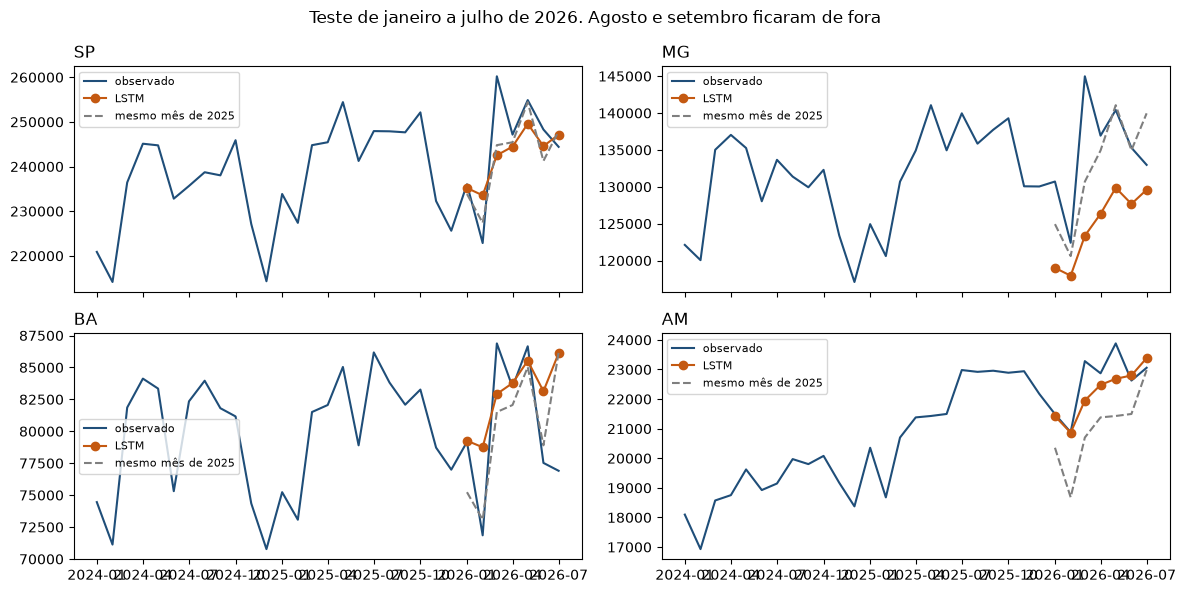

In [10]:
fig, eixos = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
historia = painel.loc["2024-01-01":]
for eixo, uf in zip(eixos.ravel(), ["SP", "MG", "BA", "AM"]):
    eixo.plot(historia.index, historia[uf], color="#1f4e79", label="observado")
    eixo.plot(previsto.index, previsto[uf], color="#c45911", marker="o", label="LSTM")
    eixo.plot(
        referencia.index,
        referencia[uf],
        color="#7f7f7f",
        linestyle="--",
        label="mesmo mês de 2025",
    )
    eixo.set_title(uf, loc="left")
    eixo.legend(fontsize=8)
fig.suptitle("Teste de janeiro a julho de 2026. Agosto e setembro ficaram de fora")
fig.tight_layout()
fig.savefig(PASTA / "teste_2026_exemplos.png", dpi=120, bbox_inches="tight")
plt.show()
